In [41]:
from __future__ import annotations
from typing import TypedDict, List, Annotated, Literal, Optional
import operator

from pydantic import Field, BaseModel
from langgraph.graph import START, END, StateGraph
from langgraph.types import Send

from langchain_groq import ChatGroq
from langchain_google_genai import ChatGoogleGenerativeAI
from langchain_core.messages import SystemMessage, HumanMessage

from langchain_community.tools.tavily_search import TavilySearchResults

from dotenv import load_dotenv
load_dotenv()

from pathlib import Path
import os

In [42]:
class FlowNode(BaseModel):
    id: str
    label: str


class FlowEdge(BaseModel):
    source: str
    target: str
    label: str = ""


class FlowchartSpec(BaseModel):
    nodes: List[FlowNode]
    edges: List[FlowEdge]

In [ ]:
class Task(BaseModel):
    id: int
    title: str

    goal: str = Field(description="One sentence describing what the reader should be able to do/understand after this section.",)
    bullets: List[str] = Field(
        min_length=3,
        max_length=5,
        description="3–5 concrete, non-overlapping subpoints to cover in this section.",
    )
    target_words: int = Field(description="Target word count for this section (120–300).")

    tags: List[str] = Field(default_factory=list)
    requires_research: bool = False
    requires_citations: bool = False
    requires_code: bool = False


class Plan(BaseModel):
    blog_title: str
    audience: str
    tone: str
    blog_kind: Literal["explainer", "tutorial", "news_roundup", "comparison", "system_design"] = "explainer"
    constraints: List[str] = Field(default_factory=list)
    tasks: List[Task]


class EvidenceItem(BaseModel):
    title: str
    url: str
    published_at: Optional[str] = None  
    snippet: Optional[str] = None
    source: Optional[str] = None


class RouterDecision(BaseModel):
    needs_research: bool
    mode: Literal["closed_book", "hybrid", "open_book"]
    queries: List[str] = Field(default_factory=list)


class EvidencePack(BaseModel):
    evidence: List[EvidenceItem] = Field(default_factory=list)

class ImageSpec(BaseModel):
    placeholder: str = Field(description="examples= [[IMAGE_1]]")
    filename: str = Field(description="Save under images/ example = abc_flow.png")
    alt: str
    caption: str
    prompt: str = Field(description="Prompt to send to the image model for images")
    size: Literal["1024x1024", "1024x1536", "1536x1536"] = "1024x1024"
    quality: Literal["low", "medium", "high"] = "medium"
    image_type: Literal[ "technical", "decorative"]

    flowchart: FlowchartSpec | None = Field(default=None, description="Required for technical images. Must be null for decorative images.")

class GlobalImagePlan(BaseModel):
    md_with_placeholders: str
    images: List[ImageSpec] = Field(default_factory=list)

In [44]:
class State(TypedDict):
    topic: str

    # routing / research
    mode: str
    needs_research: bool
    queries: List[str]
    evidence: List[EvidenceItem]
    plan: Optional[Plan]

    # workers
    sections: Annotated[List[tuple[int, str]], operator.add]  # (task_id, section_md)

    # reducer / image
    merged_md: str
    md_with_placeholders: str
    image_specs: List[dict]

    generated_images: list[dict[str, str]]

    final: str    

In [45]:
# llm = ChatGroq(model="openai/gpt-oss-120b")
llm = ChatGoogleGenerativeAI(model="gemini-3.5-flash-lite")

In [46]:
ROUTER_SYSTEM = """You are a routing module for a technical blog planner.

Decide whether web research is needed BEFORE planning.

Modes:
- closed_book (needs_research=false):
  Evergreen topics where correctness does not depend on recent facts (concepts, fundamentals).
- hybrid (needs_research=true):
  Mostly evergreen but needs up-to-date examples/tools/models to be useful.
- open_book (needs_research=true):
  Mostly volatile: weekly roundups, "this week", "latest", rankings, pricing, policy/regulation.

If needs_research=true:
- Output 3–5 high-signal queries.
- Queries should be scoped and specific (avoid generic queries like just "AI" or "LLM").
- If user asked for "last week/this week/latest", reflect that constraint IN THE QUERIES.
"""

def router_node(state:State) -> dict:
    topic = state['topic']
    decider = llm.with_structured_output(RouterDecision)
    decision = decider.invoke(
        [
            SystemMessage(content=ROUTER_SYSTEM),
            HumanMessage(content=f"Topic: {topic}")
        ]
    )

    return{
        "needs_research":decision.needs_research,
        "mode":decision.mode,
        "queries":decision.queries
    }

def route_next(state:State) -> str:
    return "research" if state['needs_research'] else "orchestrator"

RESEARCH NODE

In [47]:
def _tavily_search(query: str, max_results: int = 3) -> List[dict]:
    
    tool = TavilySearchResults(max_results=max_results)
    results = tool.invoke({"query": query})

    normalized: List[dict] = []
    for r in results or []:
        normalized.append(
            {
                "title": r.get("title") or "",
                "url": r.get("url") or "",
                "snippet": r.get("content") or r.get("snippet") or "",
                "published_at": r.get("published_date") or r.get("published_at"),
                "source": r.get("source"),
            }
        )
    return normalized


RESEARCH_SYSTEM = """You are a research synthesizer for technical writing.

Given raw web search results, produce a deduplicated list of EvidenceItem objects.

Rules:
- Only include items with a non-empty url.
- Prefer relevant + authoritative sources (company blogs, docs, reputable outlets).
- If a published date is explicitly present in the result payload, keep it as YYYY-MM-DD.
  If missing or unclear, set published_at=null. Do NOT guess.
- Keep snippets short.
- Deduplicate by URL.
"""

def research_node(state: State) -> dict:

    queries = (state.get("queries", [] or []))
    max_results = 2

    raw_results: List[dict] = []

    for q in queries:
        raw_results.extend(_tavily_search(q, max_results=max_results))

    if not raw_results:
        return {"evidence": []}

    extractor = llm.with_structured_output(EvidencePack)
    pack = extractor.invoke(
        [
            SystemMessage(content=RESEARCH_SYSTEM),
            HumanMessage(content=f"Raw results:\n{raw_results}"),
        ]
    )

    # Deduplicate by URL
    dedup = {}
    for e in pack.evidence:
        if e.url:
            dedup[e.url] = e

    return {"evidence": list(dedup.values())}

ORCHESTRATOR - MAKES PLAN FOR THE BLOG AND STORES IN PLAN OBJECT

In [48]:
ORCHESTRATION_SYSTEM = """ 
"You are a senior technical writer and developer advocate. Your job is to produce a "
                    "highly actionable outline for a technical blog post.\n\n"
                    "Hard requirements:\n"
                    "- Create 3-5 sections (tasks) that fit a technical blog.\n"
                    "- Each section must include:\n"
                    "  1) goal (1 sentence: what the reader can do/understand after the section)\n"
                    "  2) 2-3 bullets that are concrete, specific, and non-overlapping\n"
                    "  3) target word count (120–300)\n"
                    "- Include EXACTLY ONE section with section_type='common_mistakes'.\n\n"
                    "Make it technical (not generic):\n"
                    "- Assume the reader is a developer; use correct terminology.\n"
                    "- Prefer design/engineering structure: problem → intuition → approach → implementation → "
                    "trade-offs → testing/observability → conclusion.\n"
                    "- Bullets must be actionable and testable (e.g., 'Show a minimal code snippet for X', "
                    "'Explain why Y fails under Z condition', 'Add a checklist for production readiness').\n"
                    "- Explicitly include at least ONE of the following somewhere in the plan (as bullets):\n"
                    "  * a minimal working example (MWE) or code sketch\n"
                    "  * edge cases / failure modes\n"
                    "  * performance/cost considerations\n"
                    "  * security/privacy considerations (if relevant)\n"
                    "  * debugging tips / observability (logs, metrics, traces)\n"
                    "- Avoid vague bullets like 'Explain X' or 'Discuss Y'. Every bullet should state what "
                    "to build/compare/measure/verify.\n\n"
                    "Ordering guidance:\n"
                    "- Start with a crisp intro and problem framing.\n"
                    "- Build core concepts before advanced details.\n"
                    "- Include one section for common mistakes and how to avoid them.\n"
                    "- End with a practical summary/checklist and next steps.\n\n"
                    "Output must strictly match the Plan schema."
            """

def orchestrator_node(state: State):
    planner = llm.with_structured_output(Plan)

    evidence = state.get("evidence", [])
    mode = state.get("mode", "closed_book")

    plan = planner.invoke(
        [
            SystemMessage(content=ORCHESTRATION_SYSTEM),
            HumanMessage(
                content=(
                    f"Topic: {state['topic']}\n"
                    f"Mode: {mode}\n\n"
                    f"Evidence (ONLY use for fresh claims; may be empty):\n"
                    f"{[e.model_dump() for e in evidence]}"
                )
            ),
        ]
    )

    return {"plan": plan}

FANOUT - THE NUMBER OF WORKER DEPENDS ON THE NUMBER OF BLOG SECTION, IT IS DECIDED DYNAMICALLY

- Each worker knows it's task to perform, entire blog topic, entire blog plan; So that it can do it's worker properly

In [49]:
def fanout(state: State):
    return [
        Send(
            "worker",
            {
                "task": task.model_dump(),
                "topic": state["topic"],
                "mode": state["mode"],
                "plan": state["plan"].model_dump(),
                "evidence": [e.model_dump() for e in state.get("evidence", [])],
            },
        )
        for task in state["plan"].tasks
    ]

In [50]:
WORKER_SYSTEM = """You are a senior technical writer and developer advocate.
Write ONE section of a technical blog post in Markdown.

Hard constraints:
- Follow the provided Goal and cover ALL Bullets in order (do not skip or merge bullets).
- Stay close to Target words (±15%).
- Output ONLY the section content in Markdown (no blog title H1, no extra commentary).
- Start with a '## <Section Title>' heading.

Scope guard:
- If blog_kind == "news_roundup": do NOT turn this into a tutorial/how-to guide.
  Do NOT teach web scraping, RSS, automation, or "how to fetch news" unless bullets explicitly ask for it.
  Focus on summarizing events and implications.

Grounding policy:
- If mode == open_book:
  - Do NOT introduce any specific event/company/model/funding/policy claim unless it is supported by provided Evidence URLs.
  - For each event claim, attach a source as a Markdown link: ([Source](URL)).
  - Only use URLs provided in Evidence. If not supported, write: "Not found in provided sources."
- If requires_citations == true:
  - For outside-world claims, cite Evidence URLs the same way
- Evergreen reasoning is OK without citations unless requires_citations is true.

Code:
- If requires_code == true, include at least one minimal, correct code snippet relevant to the bullets.

Style:
- Short paragraphs, bullets where helpful, code fences for code.
- Avoid fluff/marketing. Be precise and implementation-oriented.
"""

def worker_node(payload: dict) -> dict:
    
    task = Task(**payload["task"])
    plan = Plan(**payload["plan"])
    evidence = [EvidenceItem(**e) for e in payload.get("evidence", [])]
    topic = payload["topic"]
    mode = payload.get("mode", "closed_book")

    bullets_text = "\n- " + "\n- ".join(task.bullets)

    evidence_text = ""
    if evidence:
        evidence_text = "\n".join(
            f"- {e.title} | {e.url} | {e.published_at or 'date:unknown'}".strip()
            for e in evidence[:20]
        )

    response = llm.invoke(
        [
            SystemMessage(content=WORKER_SYSTEM),
            HumanMessage(
                content=(
                    f"Blog title: {plan.blog_title}\n"
                    f"Audience: {plan.audience}\n"
                    f"Tone: {plan.tone}\n"
                    f"Blog kind: {plan.blog_kind}\n"
                    f"Constraints: {plan.constraints}\n"
                    f"Topic: {topic}\n"
                    f"Mode: {mode}\n\n"
                    f"Section title: {task.title}\n"
                    f"Goal: {task.goal}\n"
                    f"Target words: {task.target_words}\n"
                    f"Tags: {task.tags}\n"
                    f"requires_research: {task.requires_research}\n"
                    f"requires_citations: {task.requires_citations}\n"
                    f"requires_code: {task.requires_code}\n"
                    f"Bullets:{bullets_text}\n\n"
                    f"Evidence (ONLY use these URLs when citing):\n{evidence_text}\n"
                )
            ),
        ]
    )    
    
    # Convert Gemini's content into a normal string
    if isinstance(response.content, str):
        section_md = response.content.strip()

    elif isinstance(response.content, list):
        section_md = "\n".join(
            block["text"]
            for block in response.content
            if isinstance(block, dict)
            and block.get("type") == "text"
            and block.get("text")
        ).strip()

    else:
        raise TypeError(
            f"Unexpected response.content type: {type(response.content)}"
        )

    return {"sections": [(task.id, section_md)]}

In [51]:
import re

REDUCER - STITCHES ALL THE SECTIONS FROM THE WOKER AND CONCATINATE'S IT

- Subgraph 
- merge_content -> decide_images -> generate_and_place_images

In [52]:
def merge_content(state: State) -> dict:

    plan = state["plan"]
    
    ordered_sections = [md for _, md in sorted(state["sections"], key=lambda x: x[0])]
    body = "\n\n".join(ordered_sections).strip()
    merged_md = f"# {plan.blog_title}\n\n{body}\n"

    return {"merged_md":merged_md}


In [ ]:
# IMAGE_PLANNER_SYSTEM = """
# You are an expert content editor and visual planner.

# Analyze the provided Markdown article and determine whether visual content
# would materially improve the reader's understanding.

# For every visual you decide to create, return an ImageSpec.

# There are TWO fundamentally different visual types:

# ==================================================
# 1. TECHNICAL
# ==================================================

# Use image_type="technical" ONLY when the visual represents
# STRUCTURED INFORMATION that is better understood as a diagram.

# Examples:

# - system architecture
# - software architecture
# - data pipelines
# - ML pipelines
# - workflows
# - process flows
# - decision trees
# - agent/tool interaction graphs
# - RAG pipelines
# - MLOps pipelines
# - component relationships
# - state transitions
# - sequential technical processes

# A technical visual MUST communicate explicit relationships between
# multiple components.

# If the visual would still make sense without arrows, nodes,
# connections, or structured relationships, it is probably NOT technical.

# For technical images:

# - flowchart must contain the structured FlowchartSpec.
# - Identify important components as nodes.
# - Each node must have a unique ID and concise label.
# - Identify important connections between nodes.
# - Use source and target IDs for every connection.
# - Use edge labels for decision branches such as Yes/No.
# - Do not generate Mermaid code.
# - Do not generate Graphviz/DOT code.
# - Do not include styling instructions.
# - Do not invent components or relationships.


# ==================================================
# 2. DECORATIVE
# ==================================================

# Use image_type="decorative" when the visual is primarily intended
# to make the article more engaging, memorable, or visually appealing.

# Examples:

# - conceptual AI illustrations
# - futuristic AI scenes
# - robots or AI agents
# - abstract representations of intelligence
# - human-AI interaction scenes
# - technology-themed hero images
# - conceptual representations of an idea
# - visual metaphors
# - atmospheric illustrations
# - article header/hero images

# A decorative visual does NOT need explicit nodes, arrows,
# connections, or structured information.

# For decorative images:

# - flowchart must be null.
# - prompt must contain the detailed FLUX image-generation prompt.


# ==================================================
# IMPORTANT DECISION RULE
# ==================================================

# Do NOT classify an image as technical merely because the article
# is about a technical subject.

# The SUBJECT of the article does NOT determine image_type.

# Instead, classify based on the PURPOSE of the visual.

# For example:

# "Agentic AI" is a technical subject.

# But:

# "A futuristic AI agent interacting with tools and reasoning"
# is DECORATIVE.

# Whereas:

# "User → Agent → Tool Selection → Tool Execution → Final Response"
# is TECHNICAL.

# Similarly:

# "RAG" is a technical subject.

# "A futuristic illustration representing an AI reading documents"
# is DECORATIVE.

# Whereas:

# "Query → Retriever → Vector Database → Context → LLM → Answer"
# is TECHNICAL.


# ==================================================
# IMAGE SELECTION
# ==================================================

# First determine whether a visual is actually useful.

# Do NOT generate an image for every section.

# Only create an image when it materially improves the article.

# Then determine whether the visual is technical or decorative.

# Use this decision process:

# 1. Does the visual need explicit relationships, connections,
#    sequence, nodes, or decision branches?
#       → TECHNICAL

# 2. Is the visual mainly conceptual, atmospheric, illustrative,
#    metaphorical, or decorative?
#       → DECORATIVE

# 3. Is the article itself technical but the proposed visual is
#    merely a conceptual illustration?
#       → DECORATIVE

# 4. If both could work, choose the type that communicates the
#    specific idea more clearly.

# Do not create both technical and decorative versions of the same
# concept unless they provide substantially different information.


# ==================================================
# TECHNICAL FLOWCHART
# ==================================================

# For technical flowcharts:

# 1. Identify the main entities/components.
# 2. Identify how they interact.
# 3. Determine the direction of information/control flow.
# 4. Represent the relationships as nodes and edges.
# 5. Use concise labels.
# 6. Preserve terminology from the article.
# 7. Do not invent components.
# 8. Represent decisions explicitly.
# 9. Represent loops explicitly.
# 10. Keep the diagram readable.


# ==================================================
# COMMON IMAGE FIELDS
# ==================================================

# For every image:

# - placeholder must be unique:
#   [[IMAGE_1]], [[IMAGE_2]], etc.

# - after_heading must exactly match an existing ## heading.

# - filename must be unique.

# - alt text must accurately describe the visual.

# - caption must briefly explain what the visual represents.

# - image_type must be either "technical" or "decorative".

# - For decorative images:
#     prompt = detailed FLUX image-generation prompt
#     flowchart = null

# - For technical images:
#     prompt = ""
#     flowchart = valid FlowchartSpec

# Return only the structured GlobalImagePlan.
# """

In [ ]:
IMAGE_PLANNER_SYSTEM = """
You are an expert technical content editor and visual planner.

Analyze the Markdown article and decide whether visuals would improve
understanding. Create ImageSpec objects only when a visual adds value.

There are TWO visual types:

1. TECHNICAL
Use image_type="technical" when the visual represents structured
information such as:
- workflows
- system architectures
- pipelines
- process flows
- decision trees
- component interactions
- agent/tool workflows
- RAG or MLOps pipelines

Technical visuals require explicit nodes, connections, or directional flow.
Their `flowchart` field must contain a valid FlowchartSpec.
Their `prompt` must be empty.

2. DECORATIVE
Use image_type="decorative" for conceptual, illustrative, atmospheric,
or visually engaging images such as:
- AI/technology concepts
- futuristic scenes
- human-AI interaction
- robots or AI agents
- visual metaphors
- hero/header illustrations

Decorative visuals do NOT represent structured relationships.
Their `flowchart` field must be null.
Their `prompt` must contain a detailed FLUX image-generation prompt.

IMPORTANT:
Do not classify an image as technical just because the article is about
a technical subject.

Classify based on the PURPOSE of the visual:

"Agent → Tool → Execution → Response"
→ technical

"Futuristic AI agent interacting with tools"
→ decorative

"Query → Retriever → Vector DB → LLM → Answer"
→ technical

"AI system visually analyzing a collection of documents"
→ decorative

When uncertain, choose the visual type that best matches the intended
purpose rather than the article's subject.

IMAGE REQUIREMENTS:
- placeholder must be unique: [[IMAGE_1]], [[IMAGE_2]], ...
- after_heading must exactly match an existing ## heading.
- filename must be unique.
- alt and caption must accurately describe the visual.
- Technical: flowchart = valid FlowchartSpec, prompt = "".
- Decorative: flowchart = null, prompt = detailed FLUX prompt.
- Do not invent technical components or relationships not supported
  by the article.
- Do not generate Mermaid or Graphviz code.
- Return only the structured GlobalImagePlan.
"""

In [54]:
def decide_images(state: State) -> dict:
    plan = state["plan"]
    assert plan is not None
    merged_md = state["merged_md"]

    planner = llm.with_structured_output(GlobalImagePlan)
    try:
        image_plan = planner.invoke(
            [
                SystemMessage(content=IMAGE_PLANNER_SYSTEM),
                HumanMessage(
                    content=(
                        f"Blog kind: {plan.blog_kind}\n"
                        f"Topic: {state['topic']}\n\n"
                        "Insert placeholders + propose image prompts.\n\n"
                        f"{merged_md}"
                    )
                ),
            ]
        )
    except Exception:
        # if the planner fails, ship the blog without images
        return {"md_with_placeholders": merged_md, "image_specs": []}


    return{
            "md_with_placeholders":image_plan.md_with_placeholders,
            "image_specs": [img.model_dump() for img in image_plan.images]
        }
    

In [55]:
from huggingface_hub import InferenceClient

def _huggingface_generate_image(prompt: str):
    """
    Generate an image using FLUX.1-schnell through
    Hugging Face Inference Providers.

    Requires:
        HUGGINGFACEHUB_API_TOKEN
    """

    api_key = os.environ.get("HUGGINGFACEHUB_API_TOKEN")

    if not api_key:
        raise RuntimeError(
            "HUGGINGFACEHUB_API_TOKEN is not set."
        )

    client = InferenceClient(
        api_key=api_key
    )

    image = client.text_to_image(
        prompt=prompt,
        model="black-forest-labs/FLUX.1-schnell"
    )

    return image

In [56]:
from graphviz import Digraph


def render_flowchart(spec: FlowchartSpec, output_path: str):

    dot = Digraph(format="svg")

    dot.attr(
        rankdir="TB",
        splines="ortho"
    )

    dot.attr(
        "node",
        shape="box",
        style="rounded"
    )

    for node in spec.nodes:
        dot.node(
            node.id,
            node.label
        )

    for edge in spec.edges:
        dot.edge(
            edge.source,
            edge.target,
            label=edge.label
        )

    dot.render(
        output_path,
        cleanup=True
    )

In [ ]:
def generate_images(state: State):

    image_specs = state["image_specs"]

    generated_images = []

    for spec in image_specs:

        
        # TECHNICAL → GRAPHVIZ
        
        if spec["image_type"] == "technical":

            flowchart_data = spec.get("flowchart")

            if not flowchart_data:
                raise ValueError(
                    f"No flowchart specification found for "
                    f"{spec['filename']}"
                )

            flowchart_spec = FlowchartSpec.model_validate(
                flowchart_data
            )

            output_path = (
                Path("images") /
                Path(spec["filename"]).with_suffix("")
            )

            output_path.parent.mkdir(
                parents=True,
                exist_ok=True
            )

            render_flowchart(
                flowchart_spec,
                str(output_path)
            )

            path = str(output_path) + ".svg"


        # DECORATIVE → FLUX

        elif spec["image_type"] == "decorative":

            image = _huggingface_generate_image(
                spec["prompt"]
            )

            output_path = Path("images") / spec["filename"]

            output_path.parent.mkdir(
                parents=True,
                exist_ok=True
            )

            image.save(output_path)

            path = str(output_path)


        else:
            raise ValueError(
                f"Unknown image type: {spec['image_type']}"
            )


        generated_images.append({
            "placeholder": spec["placeholder"],
            "path": path,
            "alt": spec["alt"],
            "caption": spec["caption"]
        })


    return {
        "generated_images": generated_images
    }

In [ ]:
def replace_image_placeholders(state: State):

    md = state["md_with_placeholders"]

    for image in state["generated_images"]:

        markdown_image = (
            f"![{image['alt']}]"
            f"({image['path']})\n\n"
            f"*{image['caption']}*"
        )

        md = md.replace(image["placeholder"],markdown_image)

    plan = state['plan']
    filename = f"{plan.blog_title}.md"
    
    Path(filename).write_text(
            md,
            encoding="utf-8"
        )

    return {"final": md}

SUBGRAPH

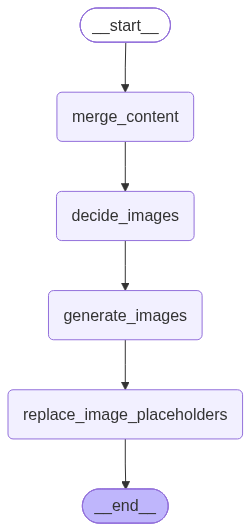

In [59]:
reducer_graph = StateGraph(State)
reducer_graph.add_node("merge_content",merge_content)
reducer_graph.add_node("decide_images",decide_images)
reducer_graph.add_node("generate_images",generate_images)
reducer_graph.add_node("replace_image_placeholders",replace_image_placeholders)

reducer_graph.add_edge(START,"merge_content")
reducer_graph.add_edge("merge_content","decide_images")
reducer_graph.add_edge("decide_images","generate_images")
reducer_graph.add_edge("generate_images","replace_image_placeholders")
reducer_graph.add_edge("replace_image_placeholders",END)

reducer_subgragh = reducer_graph.compile()

reducer_subgragh

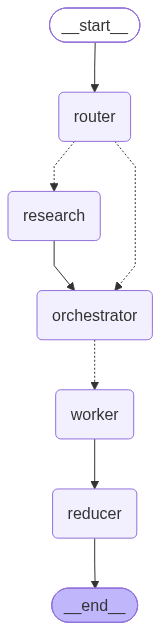

In [60]:
g = StateGraph(State)
g.add_node("router", router_node)
g.add_node("research", research_node)
g.add_node("orchestrator", orchestrator_node)
g.add_node("worker", worker_node)
g.add_node("reducer", reducer_subgragh)

g.add_edge(START, "router")
g.add_conditional_edges("router", route_next, {"research": "research", "orchestrator": "orchestrator"})
g.add_edge("research", "orchestrator")

g.add_conditional_edges("orchestrator", fanout, ["worker"])
g.add_edge("worker", "reducer")
g.add_edge("reducer", END)

app = g.compile()
app

In [61]:
def run(topic: str):
    out = app.invoke(
        {
            "topic":topic,
            "mode":"",
            "needs_research":False,
            "queries":[],
            "evidence":[],
            "plan":None,
            "sections":[],
            "merged_md":"",
            "md_with_placeholders":"",
            "image_specs":[],
            "generated_images":[],
            "final":""
        }
    )

    return out

In [ ]:
run("Decorative Blog on Agentic AI")

{'topic': 'Decorative Blog on Agentic AI',
 'mode': 'closed_book',
 'needs_research': False,
 'queries': [],
 'evidence': [],
 'plan': Plan(blog_title='Architecting Resilient Agentic AI Systems: From Prompt Chains to Autonomous Loops', audience='Software engineers and system architects', tone='Technical, pragmatic, and authoritative', blog_kind='system_design', constraints=['Must include a minimal working example', 'Must cover failure modes and debugging', 'Must feature exactly one common_mistakes section'], tasks=[Task(id=1, title='Problem Framing and Agent Loop Architecture', goal='Understand the fundamental shift from stateless request-response LLM calls to stateful, cyclic agent architectures.', bullets=['Contrast linear prompt chaining with the ReAct (Reasoning and Acting) execution loop', 'Define the core components of the agent runtime state: memory, tool registry, and execution history', 'Provide a minimal working example of a Python-based agent stepping through a single percep